# CT/MR feature PCA

Compare ISO, REL and SA using the same input for each encoder: a shared 96³ crop for CT and the complete image for MR. PCA is fitted across each input's 3D foreground; RGB colors are independent across encoders. Cyan contours provide ground-truth context.


/mnt/nvme0n1/Dataset/segmentation/projects/reform3d/src/reform3d/modules/acquisition_robustness/feature_extractor.py:182: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  check

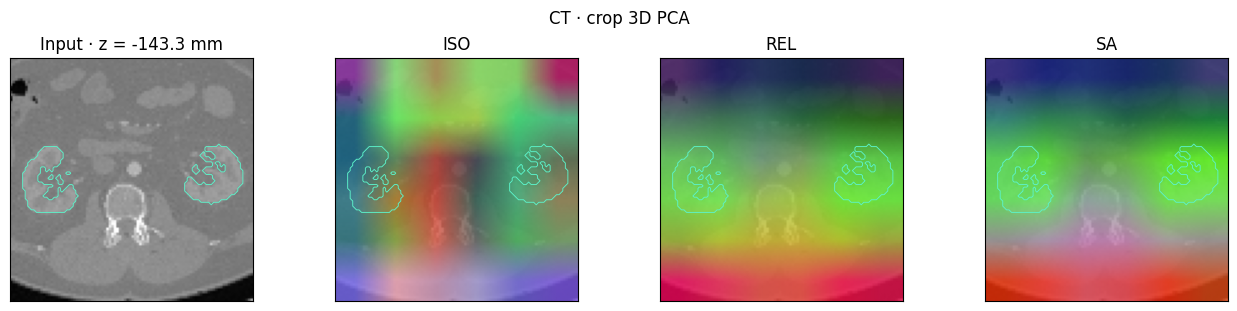

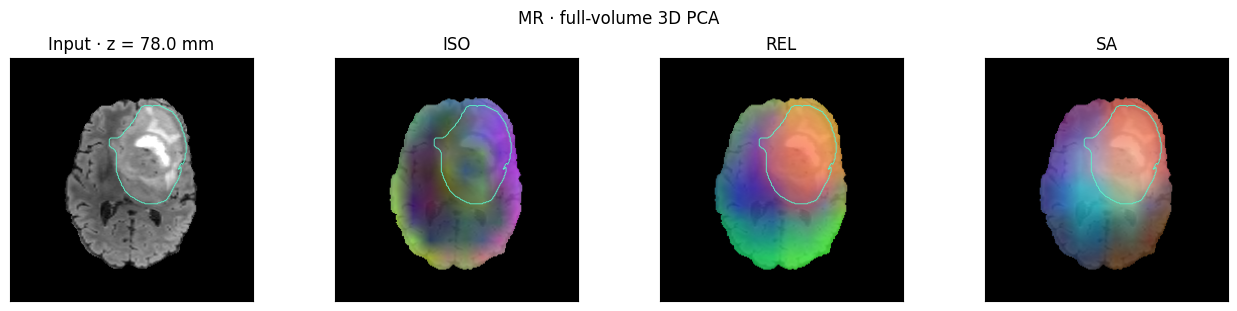

In [1]:
from pathlib import Path
import gc

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from scipy import ndimage
from sklearn.decomposition import PCA
import torch
from reform3d.encoders.factory import create_feature_extractor

# Edit paths and display settings here. Run from the repository or notebooks/.
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
examples = root / "notebooks/example_cases"
checkpoint_dir = Path("/mnt/nvme0n1/Dataset/segmentation/3D_medical_data/med3dino/med3dino_checkpoints")
checkpoints = {p.upper(): checkpoint_dir / f"med3dino_{p}/c96_{p}_teacher_checkpoint.pth"
               for p in ("iso", "rel", "sa")}
cases = {
    "CT": (examples / "CT/case_00001/case_00001_ct.nii.gz", examples / "CT/case_00001/case_00001_mask.nii.gz"),
    "MR": (examples / "MR/BraTS-GLI-00002-000/BraTS-GLI-00002-000-t2f.nii.gz", examples / "MR/BraTS-GLI-00002-000/BraTS-GLI-00002-000-seg.nii.gz"),
}

ct_foreground = "mask"  # Use "mask" for ROI or "image" for body-only cropping.
ct_margin_mm = 12.
ct_fov_mm, mr_max_axis, mr_slice_z_mm = 128., 224, 78.
device, num_slices, overlay_opacity = "cuda:0", 1, .8


def bounds(shape, affine):
    corners = np.indices((2, 2, 2)).reshape(3, -1) * np.asarray(shape)[:, None] - .5
    world = affine[:3, :3] @ corners + affine[:3, 3, None]
    return world.min(1), world.max(1)


def prepare(image, mask, modality):
    im = nib.load(image)
    seg = nib.load(mask) if mask is not None else None
    if seg is not None and (seg.shape != im.shape or not np.allclose(seg.affine, im.affine, rtol=0, atol=1e-5)):
        raise ValueError("Image and mask must have matching geometry")
    if modality == "MR":
        im = nib.as_closest_canonical(im)
        seg = nib.as_closest_canonical(seg) if seg is not None else None
    raw, source_affine = im.get_fdata(dtype=np.float32), im.affine
    labels = np.zeros(raw.shape, bool) if seg is None else np.asarray(seg.dataobj) > 0
    low, high = np.percentile(raw, [.05, 99.95])
    if modality == "CT":
        stride = np.maximum(1, np.ceil(np.array(raw.shape) / 128).astype(int))
        sampled = raw[tuple(slice(None, None, int(s)) for s in stride)]
        components, _ = ndimage.label(sampled > low + .025 * (high - low))
        counts = np.bincount(components.ravel()); counts[0] = 0
        if not counts.any():
            raise ValueError("No CT foreground found")
        body = ndimage.binary_fill_holes(components == counts.argmax()).astype(np.uint8)
        # Fit a physical cube around this case's foreground, including a margin.
        points = np.argwhere(labels) if ct_foreground == "mask" and labels.any() else np.argwhere(body) * stride
        voxel_low, voxel_high = points.min(0) - .5, points.max(0) + .5
        corners = np.indices((2, 2, 2)).reshape(3, -1) * (voxel_high - voxel_low)[:, None] + voxel_low[:, None]
        region = source_affine[:3, :3] @ corners + source_affine[:3, 3, None]
        region_low, region_high = region.min(1), region.max(1)
        center = (region_low + region_high) / 2
        fov = max(ct_fov_mm, np.max(region_high - region_low) + 2 * ct_margin_mm)
        offsets = (np.arange(96) + .5) * fov / 96 - fov / 2
        world = np.asarray(np.meshgrid(*(c + offsets for c in center), indexing="ij"))
        inverse = np.linalg.inv(source_affine)
        coords = np.einsum("ij,j...->i...", inverse[:3, :3], world) + inverse[:3, 3, None, None, None]
        volume = ndimage.map_coordinates(raw, coords, order=1, mode="constant", cval=float(low))
        mask_grid = ndimage.map_coordinates(labels, coords, order=0)
        foreground = ndimage.map_coordinates(body, coords / stride[:, None, None, None], order=0).astype(bool)
        affine = np.diag([fov / 96] * 3 + [1.])
        affine[:3, 3] = center + offsets[0]
    else:
        lo, hi = bounds(raw.shape, source_affine)
        spacing = np.max(hi - lo) / mr_max_axis
        shape = ((np.ceil((hi - lo) / spacing - 1e-10).astype(int) + 15) // 16) * 16
        affine = np.diag([spacing] * 3 + [1.])
        affine[:3, 3] = (lo + hi) / 2 - shape * spacing / 2 + spacing / 2
        transform = np.linalg.solve(source_affine, affine)
        sigma = .5 * np.sqrt(np.maximum((spacing / np.linalg.norm(source_affine[:3, :3], axis=0)) ** 2 - 1, 0))
        filtered = ndimage.gaussian_filter(raw, sigma, mode="nearest") if (sigma > 0).any() else raw
        volume = ndimage.affine_transform(filtered, transform[:3, :3], transform[:3, 3],
                    output_shape=tuple(shape), order=1, mode="constant", cval=float(low), prefilter=False)
        mask_grid = ndimage.affine_transform(labels.astype(np.uint8), transform[:3, :3], transform[:3, 3],
                    output_shape=tuple(shape), order=0, mode="constant", cval=0, prefilter=False).astype(bool)
    volume = np.ascontiguousarray((np.clip(volume, low, high) - low) / (high - low) * 2 - 1, dtype=np.float32)
    if modality == "MR":
        foreground = volume > -.95
    # CT displays the shared crop; MR displays its complete native frame.
    display = (volume, mask_grid, affine, (-1., 1.)) if modality == "CT" else (raw, labels, source_affine, (low, high))
    return volume, foreground, affine, display


def patch_features(volume, policy, checkpoint):
    extractor = create_feature_extractor(f"med3dino_{policy.lower()}_96", checkpoint_path=checkpoint, device=device)
    with torch.inference_mode():
        x = torch.from_numpy(volume)[None, None].to(device)
        tokens = extractor.model.forward_features(x)["x_norm_patchtokens"][0].float().cpu().numpy().copy()
    del extractor, x
    gc.collect()
    if device.startswith("cuda"):
        torch.cuda.empty_cache()
    return tokens


def pca_rgb(tokens, foreground):
    grid = np.array(foreground.shape) // 16
    coverage = foreground.reshape(grid[0], 16, grid[1], 16, grid[2], 16).mean((1, 3, 5)).ravel() >= .25
    unit = tokens / np.maximum(np.linalg.norm(tokens, axis=1, keepdims=True), 1e-12)
    pca = PCA(3, svd_solver="randomized", random_state=0)
    scores = pca.fit_transform(unit[coverage])
    low, high = np.percentile(scores, [1, 99], axis=0)
    if (high - low < 1e-8).any():
        raise ValueError("Insufficient feature variation for three PCA components")
    return np.clip((pca.transform(unit) - low) / (high - low), 0, 1).reshape(*grid, 3)


def sample(array, affine, world, order=1, mode="constant", background=0.):
    inverse = np.linalg.inv(affine)
    coords = np.round((inverse[:3, :3] @ world.reshape(3, -1) + inverse[:3, 3, None]).reshape(world.shape), 7)
    if array.ndim == 4:
        return np.stack([sample(array[..., c], affine, world, order, mode) for c in range(3)], -1)
    return ndimage.map_coordinates(array, coords, order=order, mode=mode, cval=background)


def plot_pca(modality, prepared, colors):
    volume, foreground, affine, (raw, labels, native_affine, window) = prepared
    if modality == "CT":
        area = foreground.sum((0, 1))
        useful = np.flatnonzero((area > 0) & (area >= .5 * area.max()))
        indices = [volume.shape[2] // 2] if num_slices == 1 else useful[np.linspace(0, len(useful)-1, min(num_slices, len(useful))).round().astype(int)]
        levels = affine[2, 3] + np.asarray(indices) * affine[2, 2]
    else:
        offsets = [0.] if num_slices == 1 else np.linspace(-2, 2, num_slices)
        ends = native_affine[2, :3] * (np.asarray(raw.shape) - 1)
        limits = native_affine[2, 3] + [np.minimum(ends, 0).sum(), np.maximum(ends, 0).sum()]
        levels = np.unique(np.clip(mr_slice_z_mm + np.asarray(offsets) * 16 * affine[2, 2], *limits))
    lo, hi = bounds(raw.shape, native_affine)
    dx, dy = (hi[:2] - lo[:2]) / raw.shape[:2]
    x, y = np.meshgrid(np.linspace(hi[0]-dx/2, lo[0]+dx/2, raw.shape[0]),
                       np.linspace(lo[1]+dy/2, hi[1]-dy/2, raw.shape[1]))
    extent = [hi[0], lo[0], lo[1], hi[1]]
    patch_affine = affine.copy(); patch_affine[:3, :3] *= 16
    patch_affine[:3, 3] = (affine @ [7.5, 7.5, 7.5, 1.])[:3]
    fig, axes = plt.subplots(len(levels), 4, figsize=(13, 3*len(levels)), squeeze=False, layout="constrained")
    for row, z in enumerate(levels):
        world = np.stack([x, y, np.full_like(x, z)])
        gray = sample(raw, native_affine, world, background=window[0])
        contour = sample(labels, native_affine, world, order=0)
        alpha = overlay_opacity * sample(foreground, affine, world, order=0)
        for column, title in enumerate(("Input", *checkpoints)):
            ax = axes[row, column]
            ax.imshow(gray, cmap="gray", vmin=window[0], vmax=window[1], extent=extent, origin="lower")
            if column:
                ax.imshow(sample(colors[column-1], patch_affine, world, mode="nearest"), alpha=alpha, extent=extent, origin="lower")
            if contour.any() and not contour.all():
                ax.contour(contour, levels=[.5], colors=["#5cf3ca"], linewidths=.65, extent=extent, origin="lower")
            ax.set(title=f"Input · z = {z:.1f} mm" if column == 0 else title if row == 0 else "",
                   xticks=[], yticks=[], xlim=extent[:2], ylim=extent[2:])
    fig.suptitle(f"{modality} · {'crop' if modality == 'CT' else 'full-volume'} 3D PCA")
    return fig


for modality, (image, mask) in cases.items():
    prepared = prepare(image, mask, modality)
    colors = [pca_rgb(patch_features(prepared[0], policy, path), prepared[1])
              for policy, path in checkpoints.items()]
    plot_pca(modality, prepared, colors)
plt.show()
